# Credit Risk Classification

## Objective
To predict whether a customer will default in the next 2 years using historical financial and behavioral data.

## Approach
- Data cleaning and preprocessing  
- Feature engineering  
- Model building (Logistic Regression, Random Forest, XGBoost)  
- Model evaluation and selection  


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## Data Loading
Loading the raw dataset and inspecting its structure.


In [ ]:
from google.colab import files
files.upload()

In [ ]:
df = pd.read_csv('cs-training.csv')

## Data Overview
Understanding the dataset structure, data types, and initial observations.


In [ ]:
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

In [ ]:
df.shape

(150000, 12)

In [ ]:
df.columns

Index(['Unnamed: 0', 'SeriousDlqin2yrs',
       'RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents'],
      dtype='object')

## Data Cleaning & Feature Engineering

In this section, data inconsistencies are handled and domain-driven features are created.  
Cleaning and feature engineering are performed iteratively to improve data quality and predictive power.

Key steps:
- Handling missing values and invalid entries  
- Capping extreme outliers  
- Fixing delinquency-related anomalies  
- Creating new features such as delinquency flags  


In [ ]:
df = df.drop(columns=['Unnamed: 0'])

In [ ]:
df.isnull().sum()

,0
SeriousDlqin2yrs,0
RevolvingUtilizationOfUnsecuredLines,0
age,0
NumberOfTime30-59DaysPastDueNotWorse,0
DebtRatio,0
MonthlyIncome,29731
NumberOfOpenCreditLinesAndLoans,0
NumberOfTimes90DaysLate,0
NumberRealEstateLoansOrLines,0
NumberOfTime60-89DaysPastDueNotWorse,0


In [ ]:
df['MonthlyIncome']=df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())

In [ ]:
df['NumberOfDependents']=df['NumberOfDependents'].fillna(df['NumberOfDependents'].mode()[0])

In [ ]:
df.isnull().sum()

,0
SeriousDlqin2yrs,0
RevolvingUtilizationOfUnsecuredLines,0
age,0
NumberOfTime30-59DaysPastDueNotWorse,0
DebtRatio,0
MonthlyIncome,0
NumberOfOpenCreditLinesAndLoans,0
NumberOfTimes90DaysLate,0
NumberRealEstateLoansOrLines,0
NumberOfTime60-89DaysPastDueNotWorse,0


In [ ]:
df.head(10)

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
5,0,0.213179,74,0,0.375607,3500.0,3,0,1,0,1.0
6,0,0.305682,57,0,5710.000000,5400.0,8,0,3,0,0.0
7,0,0.754464,39,0,0.209940,3500.0,8,0,0,0,0.0
8,0,0.116951,27,0,46.000000,5400.0,2,0,0,0,0.0
9,0,0.189169,57,0,0.606291,23684.0,9,0,4,0,2.0


In [ ]:
df['SeriousDlqin2yrs'].value_counts(normalize=True)*100

,proportion
SeriousDlqin2yrs,
0,93.316
1,6.684


### Observations During Data Preparation

The following visualizations are used to understand distributions, detect outliers, and guide cleaning decisions such as capping and transformations.


<Axes: xlabel='SeriousDlqin2yrs'>

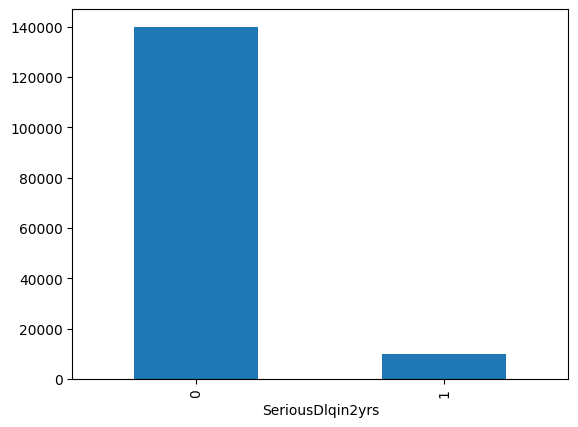

In [ ]:
df['SeriousDlqin2yrs'].value_counts().plot(kind='bar')

In [ ]:
df['RevolvingUtilizationOfUnsecuredLines'].describe()

,RevolvingUtilizationOfUnsecuredLines
count,150000.000000
mean,6.048438
std,249.755371
min,0.000000
25%,0.029867
50%,0.154181
75%,0.559046
max,50708.000000


In [ ]:
(df['RevolvingUtilizationOfUnsecuredLines']>1).sum()

np.int64(3321)

In [ ]:
df[df['RevolvingUtilizationOfUnsecuredLines']>1]['RevolvingUtilizationOfUnsecuredLines'].describe()

,RevolvingUtilizationOfUnsecuredLines
count,3321.000000
mean,259.773362
std,1659.034074
min,1.000059
25%,1.019996
50%,1.074633
75%,1.301096
max,50708.000000


In [ ]:
df['RevolvingUtilizationOfUnsecuredLines']=df['RevolvingUtilizationOfUnsecuredLines'].clip(upper=1.3)

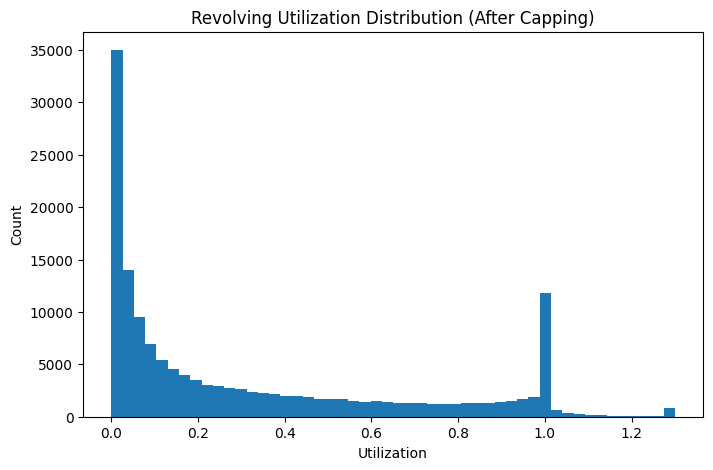

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['RevolvingUtilizationOfUnsecuredLines'], bins=50)
plt.xlabel('Utilization')
plt.ylabel('Count')
plt.title('Revolving Utilization Distribution (After Capping)')
plt.show()

Text(0, 0.5, 'Count')

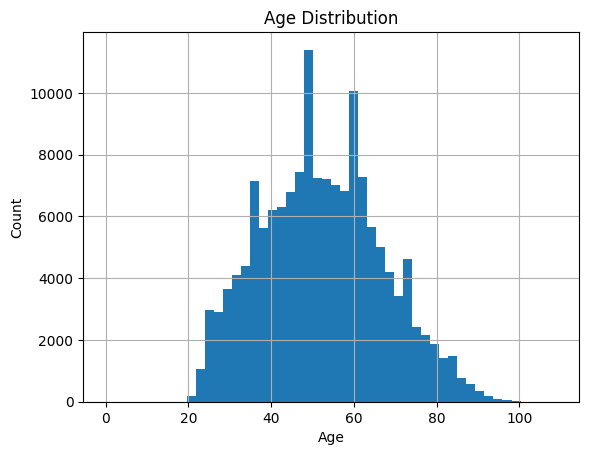

In [ ]:
df['age'].hist(bins=50)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')

In [ ]:
df['age'].isnull().sum()

np.int64(0)

In [ ]:
df['age'].describe()

,age
count,150000.000000
mean,52.295207
std,14.771866
min,0.000000
25%,41.000000
50%,52.000000
75%,63.000000
max,109.000000


In [ ]:
(df['age']==0).sum()

np.int64(1)

In [ ]:
df=df[df['age']>0]

In [ ]:
df['age'].min()

21

Text(0, 0.5, 'Count')

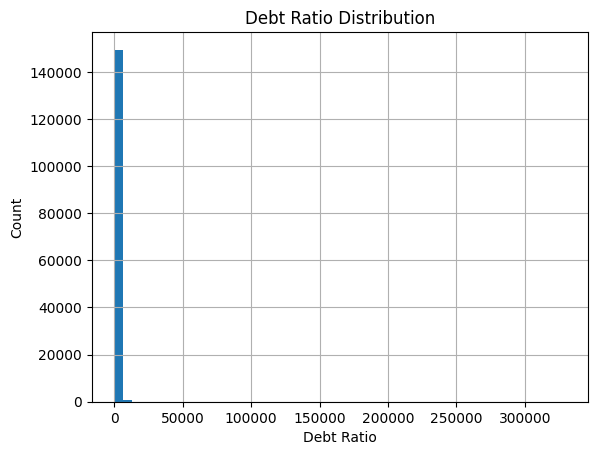

In [ ]:
df['DebtRatio'].hist(bins=50)
plt.title('Debt Ratio Distribution')
plt.xlabel('Debt Ratio')
plt.ylabel('Count')

In [ ]:
df['DebtRatio'].describe()

,DebtRatio
count,149999.000000
mean,353.007426
std,2037.825113
min,0.000000
25%,0.175074
50%,0.366503
75%,0.868257
max,329664.000000


In [ ]:
df[df['DebtRatio']>1]['DebtRatio'].describe()

,DebtRatio
count,35137.000000
mean,1505.989566
std,3999.026847
min,1.000500
25%,42.000000
50%,907.000000
75%,2210.000000
max,329664.000000


In [ ]:
df['DebtRatio']=df['DebtRatio'].clip(upper=5)

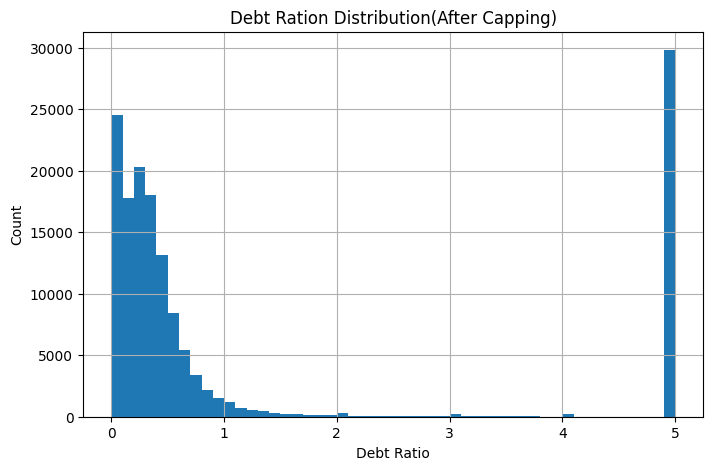

In [ ]:
plt.figure(figsize=(8,5))
df['DebtRatio'].hist(bins=50)
plt.title('Debt Ration Distribution(After Capping)')
plt.xlabel('Debt Ratio')
plt.ylabel('Count')
plt.show()

Text(0, 0.5, 'Count')

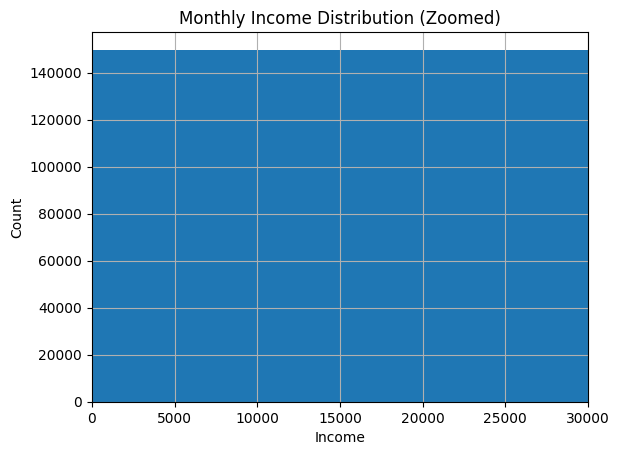

In [ ]:
df['MonthlyIncome'].hist(bins=50)
plt.xlim(0, 30000)
plt.title('Monthly Income Distribution (Zoomed)')
plt.xlabel('Income')
plt.ylabel('Count')

In [ ]:
df['MonthlyIncome'].describe()

,MonthlyIncome
count,1.499990e+05
mean,6.418458e+03
std,1.289044e+04
min,0.000000e+00
25%,3.903000e+03
50%,5.400000e+03
75%,7.400000e+03
max,3.008750e+06


In [ ]:
p99=df['MonthlyIncome'].quantile(0.99)


In [ ]:
p99

np.float64(23000.0)

In [ ]:
df['MonthlyIncome']=df['MonthlyIncome'].clip(upper=23000)

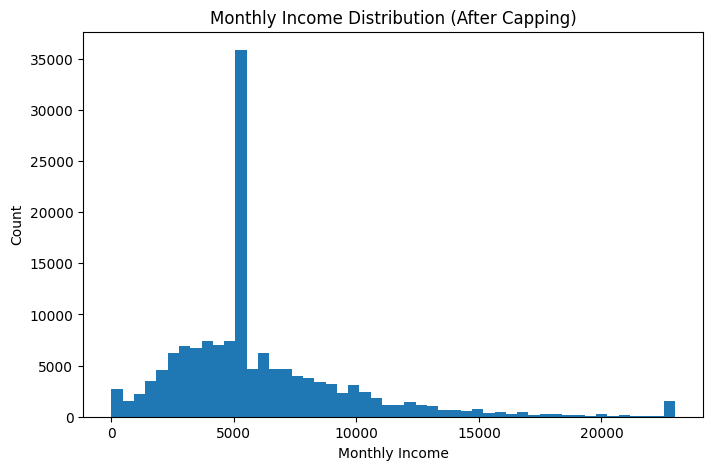

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df['MonthlyIncome'], bins=50)
plt.title('Monthly Income Distribution (After Capping)')
plt.xlabel('Monthly Income')
plt.ylabel('Count')
plt.show()

In [ ]:
df['NumberOfDependents'].isnull().sum()

np.int64(0)

In [ ]:
df['NumberOfDependents'].describe()

,NumberOfDependents
count,149999.000000
mean,0.737405
std,1.107020
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,20.000000


In [ ]:
df['NumberOfDependents'].value_counts()

,count
NumberOfDependents,
0.0,90826
1.0,26316
2.0,19521
3.0,9483
4.0,2862
5.0,746
6.0,158
7.0,51
8.0,24


In [ ]:
df['NumberOfDependents']=df['NumberOfDependents'].clip(upper=8)

In [ ]:
df['NumberOfOpenCreditLinesAndLoans'].describe()

,NumberOfOpenCreditLinesAndLoans
count,149999.000000
mean,8.452776
std,5.145964
min,0.000000
25%,5.000000
50%,8.000000
75%,11.000000
max,58.000000


In [ ]:
df['NumberOfOpenCreditLinesAndLoans'].value_counts().head(20)

,count
NumberOfOpenCreditLinesAndLoans,
6,13613
7,13245
5,12931
8,12562
4,11609
9,11355
10,9624
3,9058
11,8321


In [ ]:
(df['NumberOfOpenCreditLinesAndLoans']>20).sum()

np.int64(3980)

In [ ]:
df['NumberOfOpenCreditLinesAndLoans']=df['NumberOfOpenCreditLinesAndLoans'].clip(upper=20)

In [ ]:
df['NumberOfTime30-59DaysPastDueNotWorse'].isnull().sum()

np.int64(0)

In [ ]:
df['NumberOfTime30-59DaysPastDueNotWorse'].describe()

,NumberOfTime30-59DaysPastDueNotWorse
count,149999.000000
mean,0.421029
std,4.192795
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,98.000000


In [ ]:
df['NumberOfTime30-59DaysPastDueNotWorse'].value_counts().head(15)

,count
NumberOfTime30-59DaysPastDueNotWorse,
0,126018
1,16032
2,4598
3,1754
4,747
5,342
98,264
6,140
7,54


In [ ]:
df['NumberOfTime30-59DaysPastDueNotWorse']=df['NumberOfTime30-59DaysPastDueNotWorse'].clip(upper=10)

### Feature Creation
New variables are created based on cleaned data to capture risk behavior more effectively.


In [ ]:
df['Ever_30_59_DPD']=(df['NumberOfTime30-59DaysPastDueNotWorse']>0).astype(int)

In [ ]:
df['NumberOfTime60-89DaysPastDueNotWorse'].describe()

,NumberOfTime60-89DaysPastDueNotWorse
count,149999.000000
mean,0.240388
std,4.155193
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,98.000000


In [ ]:
df['NumberOfTime60-89DaysPastDueNotWorse'].value_counts().head(10)

,count
NumberOfTime60-89DaysPastDueNotWorse,
0,142395
1,5731
2,1118
3,318
98,264
4,105
5,34
6,16
7,9


In [ ]:
df['NumberOfTime60-89DaysPastDueNotWorse'].isnull().sum()

np.int64(0)

In [ ]:
df['NumberOfTime60-89DaysPastDueNotWorse']=df['NumberOfTime60-89DaysPastDueNotWorse'].clip(upper=10)

In [ ]:
df['Ever_60_89_DPD']=(df['NumberOfTime60-89DaysPastDueNotWorse']>0).astype(int)

In [ ]:
df['NumberOfTimes90DaysLate'].isnull().sum()

np.int64(0)

In [ ]:
df['NumberOfTimes90DaysLate'].describe()

,NumberOfTimes90DaysLate
count,149999.000000
mean,0.265975
std,4.169318
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,98.000000


In [ ]:
df['NumberOfTimes90DaysLate'].value_counts().head(10)

,count
NumberOfTimes90DaysLate,
0,141661
1,5243
2,1555
3,667
4,291
98,264
5,131
6,80
7,38


In [ ]:
df['NumberOfTimes90DaysLate']=df['NumberOfTimes90DaysLate'].clip(upper=10)

In [ ]:
df['Ever_90plus_DPD']=(df['NumberOfTimes90DaysLate']>0).astype(int)

In [ ]:
df['NumberRealEstateLoansOrLines'].isnull().sum()

np.int64(0)

In [ ]:
df['NumberRealEstateLoansOrLines'].describe()

,NumberRealEstateLoansOrLines
count,149999.000000
mean,1.018233
std,1.129772
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,54.000000


In [ ]:
df['NumberRealEstateLoansOrLines'].value_counts().head(10)

,count
NumberRealEstateLoansOrLines,
0,56188
1,52338
2,31521
3,6300
4,2170
5,689
6,320
7,171
8,93


In [ ]:
df['NumberRealEstateLoansOrLines']=df['NumberRealEstateLoansOrLines'].clip(upper=10)

In [ ]:
df['Has_RealEstate_Loan']=(df['NumberRealEstateLoansOrLines']>0).astype(int)

## Train-Test Split
Splitting the dataset into training and testing sets to evaluate model performance on unseen data.


In [ ]:
from sklearn.model_selection import train_test_split


In [ ]:
x= df.drop('SeriousDlqin2yrs', axis=1)
y= df['SeriousDlqin2yrs']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
x_train.shape, x_test.shape

((119999, 14), (30000, 14))

In [ ]:
x_train.columns

Index(['RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents', 'Ever_30_59_DPD', 'Ever_60_89_DPD',
       'Ever_90plus_DPD', 'Has_RealEstate_Loan'],
      dtype='object')

## Model Building
Training Logistic Regression, Random Forest, and XGBoost models for comparison.


### Logistic Regression


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score


## Model Evaluation

Evaluating models using Precision, Recall, F1 Score, and AUC, with focus on recall due to higher business cost of false negatives.


In [ ]:
logreg_pipeline = Pipeline([('scaler', StandardScaler()),('model', LogisticRegression(max_iter=5000, class_weight='balanced'))])
logreg_pipeline.fit(x_train,y_train)

y_pred_lr = logreg_pipeline.predict(x_test)
y_prob_lr = logreg_pipeline.predict_proba(x_test)[:,1]

print('AUC:', roc_auc_score(y_test,y_prob_lr))
print(classification_report(y_test,y_pred_lr))

AUC: 0.8637746765431482
              precision    recall  f1-score   support

           0       0.98      0.81      0.89     27995
           1       0.22      0.75      0.34      2005

    accuracy                           0.81     30000
   macro avg       0.60      0.78      0.62     30000
weighted avg       0.93      0.81      0.85     30000



In [ ]:
from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(y_test, y_pred_lr)
conf_matrix

array([[22773,  5222],
       [  500,  1505]])

### Model-Based Insights

The following plots are generated after model training to evaluate performance and understand feature importance.


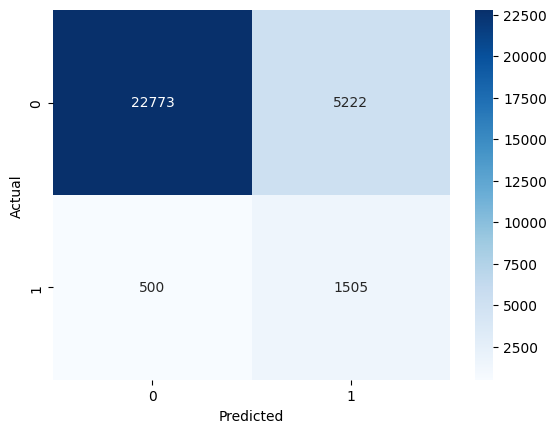

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
import pandas as pd

coefs = logreg_pipeline.named_steps['model'].coef_[0]
feature_names = x_train.columns

coef_df= pd.DataFrame({'Feature' : feature_names,
                       'Coefficient' : coefs}).sort_values(by='Coefficient', ascending=False)

coef_df

,Feature,Coefficient
0,RevolvingUtilizationOfUnsecuredLines,0.710279
12,Ever_90plus_DPD,0.377089
11,Ever_60_89_DPD,0.361939
7,NumberRealEstateLoansOrLines,0.300643
10,Ever_30_59_DPD,0.291040
5,NumberOfOpenCreditLinesAndLoans,0.218805
2,NumberOfTime30-59DaysPastDueNotWorse,0.139916
9,NumberOfDependents,0.046024
6,NumberOfTimes90DaysLate,0.042416
3,DebtRatio,-0.047205


### Threshold Exploration (Logistic Regression)

Threshold tuning is explored for Logistic Regression to understand how decision thresholds affect precision and recall.  
This is used for learning and comparison, not for final model selection.


In [ ]:
thresholds =[0.5,0.4,0.3]

for t in thresholds:
  y_pred_t = (y_prob_lr >= t).astype(int)
  print(f'\n========== Threshold ={t} ==========')
  print(classification_report(y_test,y_pred_t))



========== Threshold =0.5 ==========
              precision    recall  f1-score   support

           0       0.98      0.81      0.89     27995
           1       0.22      0.75      0.34      2005

    accuracy                           0.81     30000
   macro avg       0.60      0.78      0.62     30000
weighted avg       0.93      0.81      0.85     30000


========== Threshold =0.4 ==========
              precision    recall  f1-score   support

           0       0.98      0.73      0.84     27995
           1       0.18      0.83      0.30      2005

    accuracy                           0.74     30000
   macro avg       0.58      0.78      0.57     30000
weighted avg       0.93      0.74      0.80     30000


========== Threshold =0.3 ==========
              precision    recall  f1-score   support

           0       0.99      0.62      0.76     27995
           1       0.14      0.89      0.25      2005

    accuracy                           0.64     30000
   macro avg  

### Random Forest



In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf= RandomForestClassifier(n_estimators=300,
                           max_depth=None,
                           random_state=42,
                           class_weight='balanced',
                           n_jobs=-1)

rf.fit(x_train,y_train)

y_pred_rf= rf.predict(x_test)
y_prob_rf= rf.predict_proba(x_test)[:,1]

print('AUC:', roc_auc_score(y_test, y_prob_rf))
print(classification_report(y_test,y_pred_rf))

AUC: 0.8430960997221183
              precision    recall  f1-score   support

           0       0.94      0.99      0.97     27995
           1       0.53      0.17      0.25      2005

    accuracy                           0.93     30000
   macro avg       0.74      0.58      0.61     30000
weighted avg       0.92      0.93      0.92     30000



### XGBoost


In [ ]:
!pip install xgboost

In [ ]:
import xgboost as xgb
from xgboost import XGBClassifier

In [ ]:
xgb= XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(len(y_train)- sum(y_train))/ sum(y_train),
    objective='binary:logistic',
    random_state=42,
    n_jobs=-1
)
xgb.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:
y_pred_xgb=xgb.predict(x_test)
y_prob_xgb=xgb.predict_proba(x_test)[:,1]

In [ ]:
print('AUC:', roc_auc_score(y_test, y_prob_xgb))
print(classification_report(y_test, y_pred_xgb))

AUC: 0.8694466103004679
              precision    recall  f1-score   support

           0       0.98      0.80      0.88     27995
           1       0.22      0.78      0.34      2005

    accuracy                           0.80     30000
   macro avg       0.60      0.79      0.61     30000
weighted avg       0.93      0.80      0.85     30000



In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [ ]:
def evaluate_threshold(threshold):
  y_pred_thresh = (y_prob_xgb >= threshold).astype(int)

  precision = precision_score(y_test, y_pred_thresh)
  recall = recall_score(y_test, y_pred_thresh)
  f1 = f1_score(y_test, y_pred_thresh)

  return precision, recall, f1


## Threshold Tuning (Final Model)

Threshold tuning is applied to the selected XGBoost model to optimize the balance between false negatives and false positives based on business requirements.


In [ ]:
thresholds= [0.50, 0.40, 0.35, 0.30, 0.25]

result=[]

for t in thresholds:
  p, r, f = evaluate_threshold(t)
  result.append([t, round(p,3), round(r,3), round(f,3)])

result

[[0.5, 0.221, 0.78, 0.344],
 [0.4, 0.18, 0.848, 0.297],
 [0.35, 0.164, 0.877, 0.277],
 [0.3, 0.149, 0.896, 0.255],
 [0.25, 0.134, 0.918, 0.233]]

In [ ]:
df_thresh = pd.DataFrame(result, columns=['Threshold', 'Precision', 'Recall', 'F1'])
df_thresh

,Threshold,Precision,Recall,F1
0,0.50,0.221,0.780,0.344
1,0.40,0.180,0.848,0.297
2,0.35,0.164,0.877,0.277
3,0.30,0.149,0.896,0.255
4,0.25,0.134,0.918,0.233


In [ ]:
importances = xgb.feature_importances_
features = x_train.columns

fi_df = pd.DataFrame({
    'Feature' : features,
    'Importance' : importances
}).sort_values(by='Importance', ascending=False)

fi_df

,Feature,Importance
12,Ever_90plus_DPD,0.229696
10,Ever_30_59_DPD,0.205772
0,RevolvingUtilizationOfUnsecuredLines,0.136402
6,NumberOfTimes90DaysLate,0.127943
2,NumberOfTime30-59DaysPastDueNotWorse,0.087420
8,NumberOfTime60-89DaysPastDueNotWorse,0.068225
11,Ever_60_89_DPD,0.053430
7,NumberRealEstateLoansOrLines,0.021470
13,Has_RealEstate_Loan,0.015503
1,age,0.014722


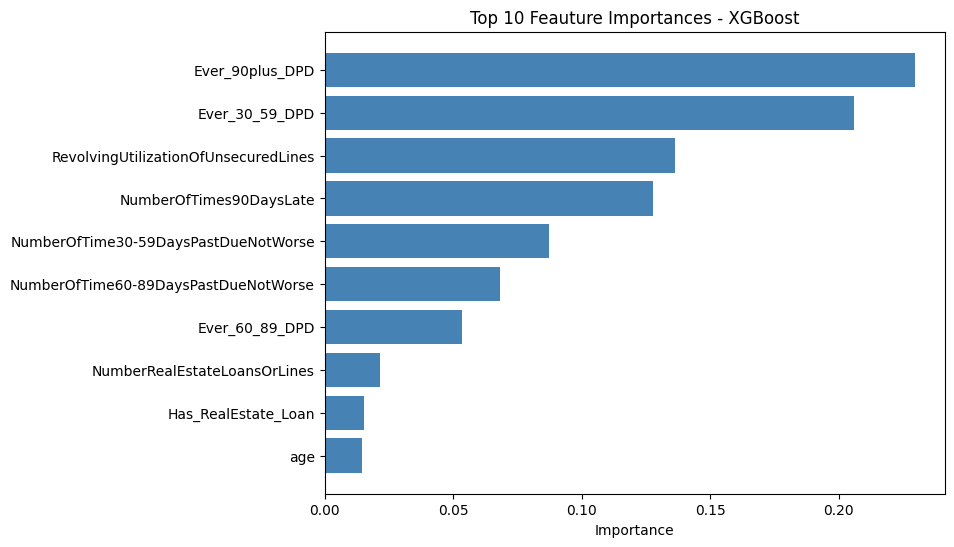

In [ ]:
top_10 = fi_df.head(10)

plt.figure(figsize=(8,6))
plt.barh(top_10['Feature'], top_10['Importance'], color='steelblue')
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.title('Top 10 Feauture Importances - XGBoost')
plt.show()

## Model Comparison

Comparing all models based on Precision, Recall, F1 Score, and AUC to select the best-performing model.


In [ ]:
models = {
    'Logistic Regression': (y_pred_lr, y_prob_lr),
    'Random Forest': (y_pred_rf, y_prob_rf),
    'XGBoost': (y_pred_xgb, y_prob_xgb)
}

rows=[]

for name, (pred, prob) in models.items():
  precision = precision_score(y_test, pred)
  recall = recall_score(y_test, pred)
  f1 = f1_score(y_test, pred)
  auc = roc_auc_score(y_test, prob)

  rows.append([name, precision, recall, f1, auc])

  compare_df=pd.DataFrame(rows, columns=['Models', 'Precision', 'Recall', 'F1 Score', 'AUC'])



In [ ]:
compare_df

,Models,Precision,Recall,F1 Score,AUC
0,Logistic Regression,0.223725,0.750623,0.344709,0.863775
1,Random Forest,0.534290,0.167082,0.254559,0.843096
2,XGBoost,0.221012,0.779551,0.344387,0.869447


## Conclusion

- XGBoost performed best in terms of AUC and recall  
- It handled class imbalance effectively  
- Delinquency history and credit utilization were the strongest predictors  
- The final model balances risk detection and false alarms appropriately  
